# Milestone 3: EDA, Analisis Temporal, dan Insight

**Tegar Reski Pratama — 202310370311215**

Jalankan setelah notebook 01 dan 02. Delapan grafik Plotly memakai agregasi seluruh
artikel bersih, bukan sampel. Grafik dan tujuh insight numerik dihitung saat eksekusi.
Analisis menggambarkan arsip dataset tahun 2017; cakupan scraping belum tentu lengkap.


In [1]:
from pathlib import Path
import sys

current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in (current, *current.parents)
     if (path / 'requirements.txt').is_file() and (path / 'data/README.md').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Buka Jupyter dari akar repository atau folder notebooks/.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import polars as pl
from IPython.display import Markdown, display
from src.common import (
    connect_analytics, prepare_directories, read_json, sha256_file,
    sink_parquet_atomic, sql_literal, write_json,
)
prepare_directories(PROJECT_ROOT)

import math
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

DATA_PATH = PROJECT_ROOT / 'data/processed/dataset_bersih.parquet'
FIGURE_DIR = PROJECT_ROOT / 'output/figures'
CLEANING = read_json(PROJECT_ROOT / 'output/cleaning_summary.json')
if not DATA_PATH.is_file():
    raise FileNotFoundError('Jalankan notebook 02 terlebih dahulu.')
assert sha256_file(DATA_PATH) == CLEANING['clean_parquet_sha256'], 'Data bersih berubah; ulangi notebook 02.'

connection = connect_analytics(PROJECT_ROOT)
connection.execute(f"""
    CREATE VIEW news AS
    SELECT row_id, published_at, published_date, month, weekday, hour, has_time,
           source, word_count, char_count, is_length_outlier, source_is_imputed
    FROM read_parquet({sql_literal(DATA_PATH)})
""")
total = connection.execute('SELECT COUNT(*) FROM news').fetchone()[0]
assert total == CLEANING['rows_clean'] and total > 0
pio.templates.default = 'plotly_white'
pio.renderers.default = 'plotly_mimetype'
DAY_NAMES = ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu']
figures = {}


def show_and_save(figure, name):
    figure.update_layout(font=dict(family='Arial', size=13), hovermode='closest')
    figure.write_html(FIGURE_DIR / f'{name}.html', include_plotlyjs=True, full_html=True)
    figures[name] = figure.layout.title.text
    figure.show()


print(f'Artikel bersih dianalisis: {total:,}')


Artikel bersih dianalisis: 455,360


## 1. Publikasi Harian dan Rata-rata Bergerak 7 Hari

Kalender memuat 365 hari. Nol berarti tidak ada artikel dalam dataset pada hari
tersebut; nol tidak membuktikan tidak ada publikasi di media asli.


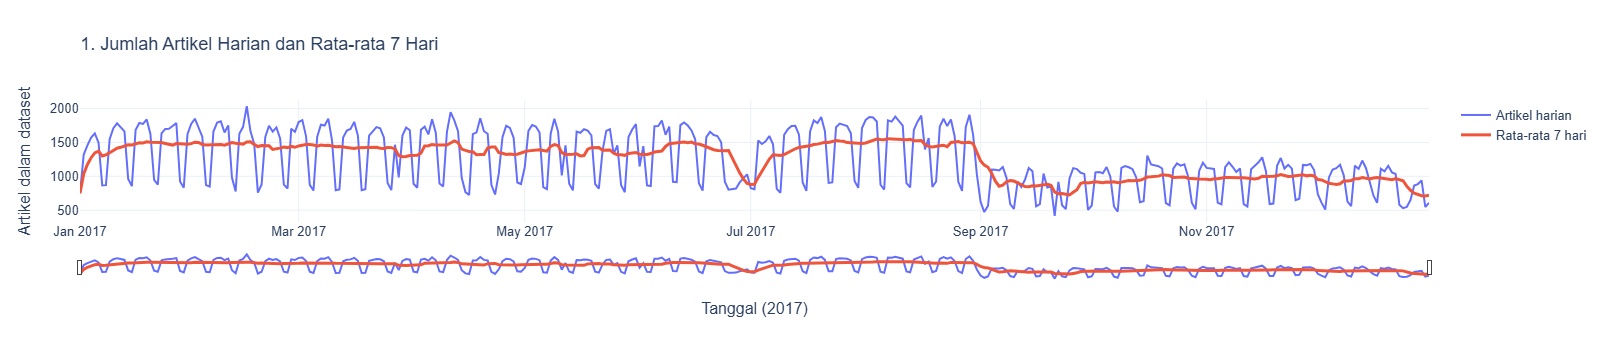

In [2]:
connection.execute("""
    CREATE TEMP TABLE calendar AS
    SELECT CAST(day AS DATE) AS tanggal,
           CAST(DATE_TRUNC('month', day) AS DATE) AS bulan,
           CAST(ISODOW(day) AS INTEGER) AS weekday
    FROM GENERATE_SERIES(DATE '2017-01-01', DATE '2017-12-31', INTERVAL 1 DAY) AS t(day)
""")
connection.execute("""
    CREATE TEMP TABLE daily_counts AS
    SELECT c.tanggal, c.bulan, c.weekday, COALESCE(n.artikel, 0) AS artikel,
           n.artikel IS NOT NULL AS ada_artikel
    FROM calendar c
    LEFT JOIN (SELECT published_date AS tanggal, COUNT(*) AS artikel
               FROM news GROUP BY published_date) n USING (tanggal)
""")
daily = connection.execute("""
    SELECT *, AVG(artikel) OVER (ORDER BY tanggal ROWS BETWEEN 6 PRECEDING AND CURRENT ROW) AS ma7
    FROM daily_counts ORDER BY tanggal
""").df()
daily.to_csv(PROJECT_ROOT / 'output/eda_daily.csv', index=False)
fig = go.Figure()
fig.add_scatter(x=daily['tanggal'], y=daily['artikel'], name='Artikel harian',
                customdata=daily[['ada_artikel']],
                hovertemplate='%{x|%d %b %Y}<br>Artikel: %{y:,}<br>Ada artikel: %{customdata[0]}<extra></extra>')
fig.add_scatter(x=daily['tanggal'], y=daily['ma7'], name='Rata-rata 7 hari', line=dict(width=3))
fig.update_layout(title='1. Jumlah Artikel Harian dan Rata-rata 7 Hari',
                  xaxis_title='Tanggal (2017)', yaxis_title='Artikel dalam dataset')
fig.update_xaxes(rangeslider_visible=True)
show_and_save(fig, '01_daily_trend')


## 2. Volume Publikasi Bulanan

Hover menampilkan jumlah hari kalender, hari yang memiliki artikel, dan rata-rata
artikel per hari kalender agar perbedaan panjang bulan dapat dinilai.


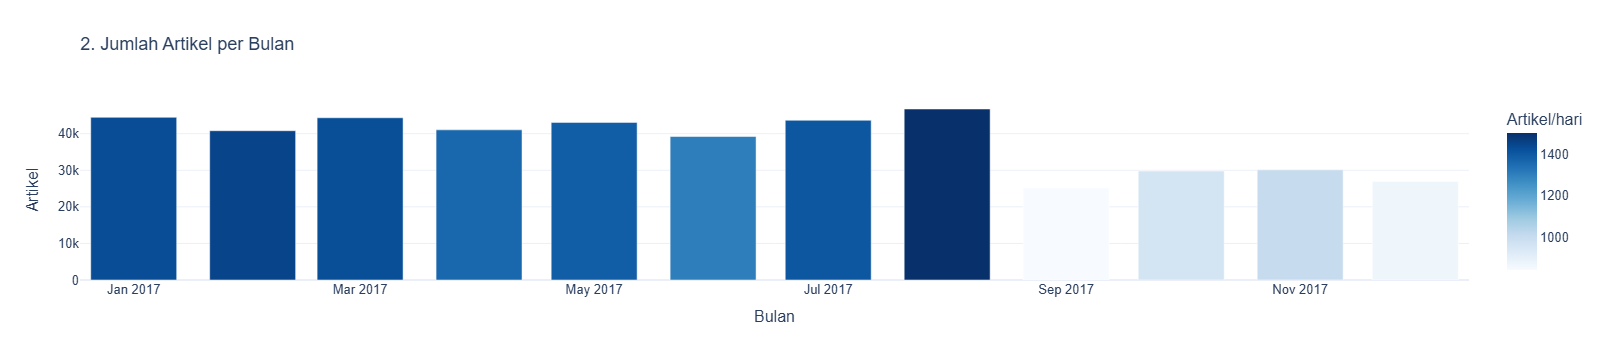

In [3]:
monthly = connection.execute("""
    SELECT bulan, SUM(artikel) AS artikel, COUNT(*) AS hari_kalender,
           COUNT(*) FILTER (WHERE ada_artikel) AS hari_teramati,
           AVG(artikel) AS rata_per_hari
    FROM daily_counts GROUP BY bulan ORDER BY bulan
""").df()
monthly['label_bulan'] = pd.to_datetime(monthly['bulan']).dt.strftime('%Y-%m')
monthly['persentase'] = monthly['artikel'] / total * 100
monthly.to_csv(PROJECT_ROOT / 'output/eda_monthly.csv', index=False)
fig = px.bar(monthly, x='label_bulan', y='artikel', color='rata_per_hari',
             hover_data=['hari_kalender', 'hari_teramati', 'persentase'],
             labels={'label_bulan': 'Bulan', 'artikel': 'Artikel', 'rata_per_hari': 'Artikel/hari'},
             title='2. Jumlah Artikel per Bulan', color_continuous_scale='Blues')
show_and_save(fig, '02_monthly_volume')


## 3. Pola Hari dalam Minggu

Bandingkan rata-rata per hari kalender, bukan jumlah mentah: jumlah Senin dan
Minggu dalam tahun 2017 berbeda. Hari kosong dalam arsip tetap masuk denominator.


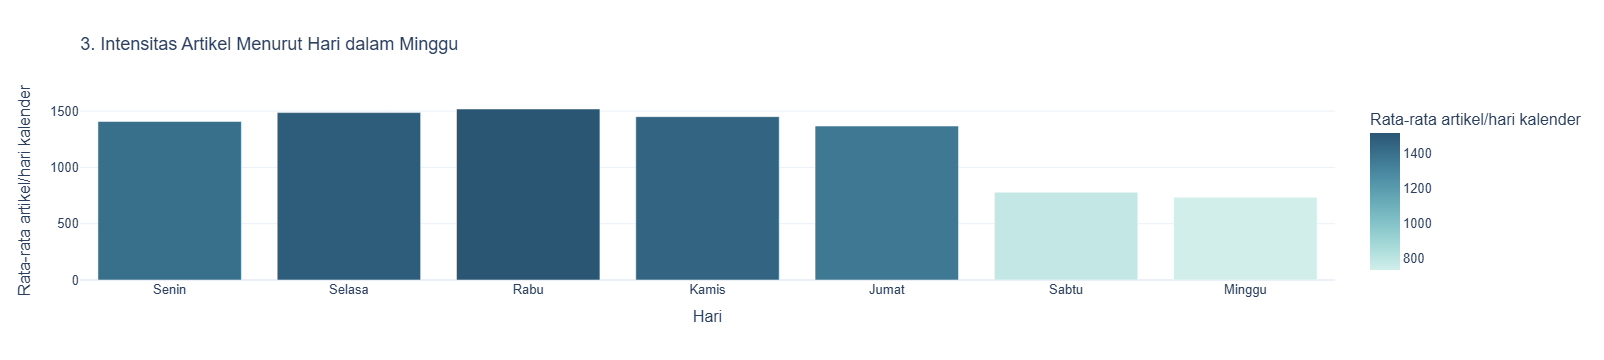

In [4]:
weekday = connection.execute("""
    SELECT weekday, SUM(artikel) AS artikel, COUNT(*) AS hari_kalender,
           COUNT(*) FILTER (WHERE ada_artikel) AS hari_teramati,
           AVG(artikel) AS rata_per_hari
    FROM daily_counts GROUP BY weekday ORDER BY weekday
""").df()
weekday['hari'] = [DAY_NAMES[int(day) - 1] for day in weekday['weekday']]
fig = px.bar(weekday, x='hari', y='rata_per_hari', hover_data=['artikel', 'hari_kalender', 'hari_teramati'],
             category_orders={'hari': DAY_NAMES}, color='rata_per_hari',
             labels={'hari': 'Hari', 'rata_per_hari': 'Rata-rata artikel/hari kalender'},
             title='3. Intensitas Artikel Menurut Hari dalam Minggu', color_continuous_scale='Teal')
show_and_save(fig, '03_weekday_pattern')


## 4. Komposisi Sumber Artikel

Sumber URL dinormalisasi menjadi domain, sedangkan nama sumber dipertahankan
sebagai label. Sepuluh sumber terbesar ditampilkan; persentase memakai seluruh korpus.


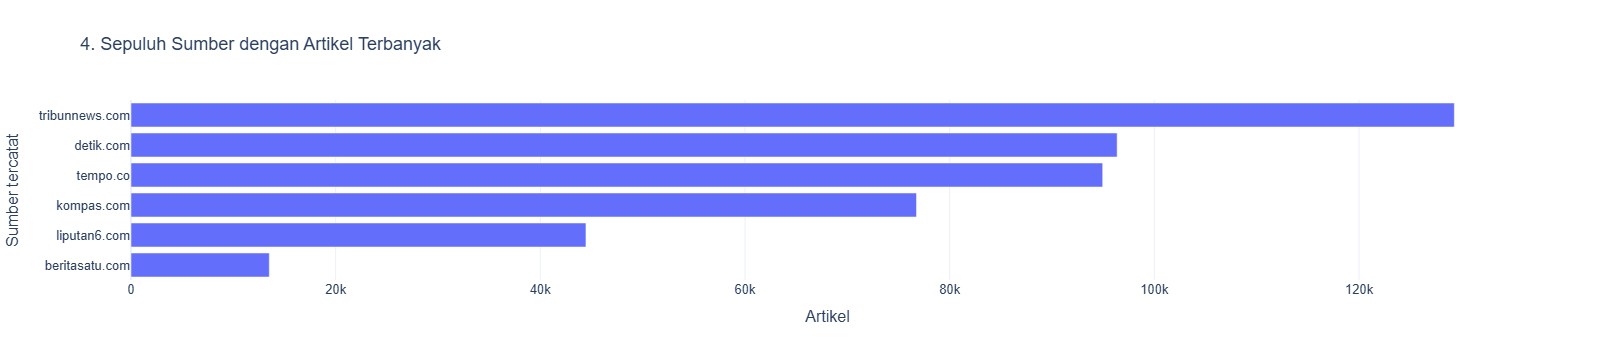

In [5]:
sources = connection.execute("""
    SELECT source AS sumber, COUNT(*) AS artikel,
           AVG(word_count) AS rata_kata,
           COUNT(*) FILTER (WHERE source_is_imputed) AS sumber_imputasi
    FROM news GROUP BY source ORDER BY artikel DESC, sumber
""").df()
sources['persentase'] = sources['artikel'] / total * 100
sources.to_csv(PROJECT_ROOT / 'output/eda_sources.csv', index=False)
top_sources = sources.head(10).sort_values(['artikel', 'sumber'], ascending=[True, True])
fig = px.bar(top_sources, x='artikel', y='sumber', orientation='h',
             hover_data=['persentase', 'rata_kata'],
             labels={'sumber': 'Sumber tercatat', 'artikel': 'Artikel'},
             title='4. Sepuluh Sumber dengan Artikel Terbanyak')
show_and_save(fig, '04_source_composition')


## 5. Heatmap Hari × Jam Publikasi

Hanya timestamp yang benar-benar mempunyai jam yang digunakan. Tanggal tanpa
jam tidak dianggap pukul 00.00. Offset eksplisit dikonversi ke WIB; timestamp tanpa
offset memakai waktu yang tercatat, dengan asumsi WIB yang perlu dikonfirmasi.


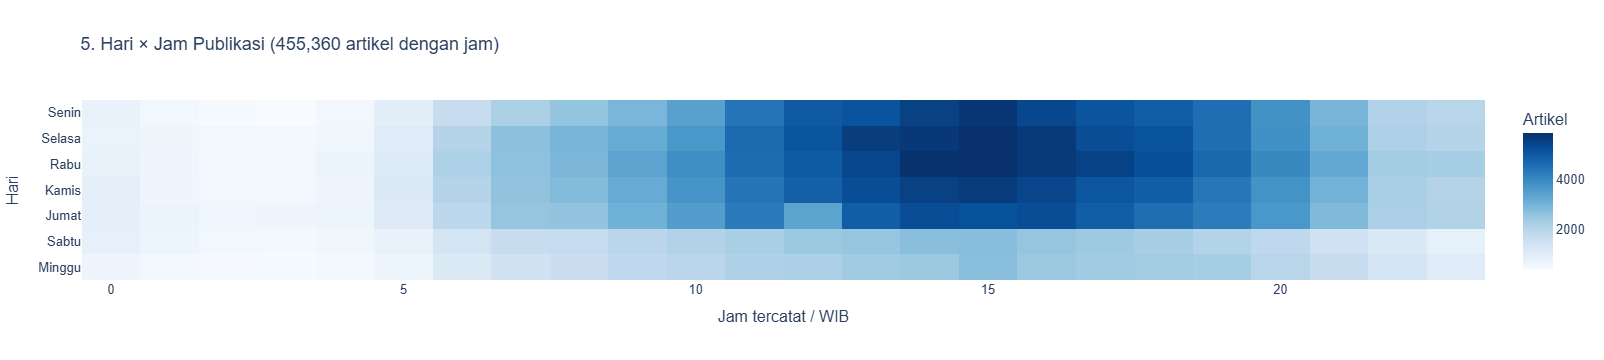

In [6]:
hourly = connection.execute("""
    SELECT weekday, hour AS jam, COUNT(*) AS artikel
    FROM news WHERE has_time AND hour IS NOT NULL
    GROUP BY weekday, hour ORDER BY weekday, hour
""").df()
known_time_rows = int(hourly['artikel'].sum())
heat = pd.DataFrame(0, index=DAY_NAMES, columns=list(range(24)))
for row in hourly.itertuples(index=False):
    heat.loc[DAY_NAMES[int(row.weekday) - 1], int(row.jam)] = int(row.artikel)
fig = px.imshow(heat, labels=dict(x='Jam tercatat / WIB', y='Hari', color='Artikel'),
                title=f'5. Hari × Jam Publikasi ({known_time_rows:,} artikel dengan jam)',
                aspect='auto', color_continuous_scale='Blues')
if known_time_rows == 0:
    fig.add_annotation(text='Dataset hanya memiliki tanggal; analisis jam tidak tersedia.',
                       xref='paper', yref='paper', x=0.5, y=0.5, showarrow=False)
show_and_save(fig, '05_weekday_hour_heatmap')


## 6. Distribusi Panjang Artikel

Histogram dihitung di DuckDB. Bin terakhir menampung semua nilai di atas batas
pembulatan persentil 99; artikel pada ekor distribusi tidak dibuang.


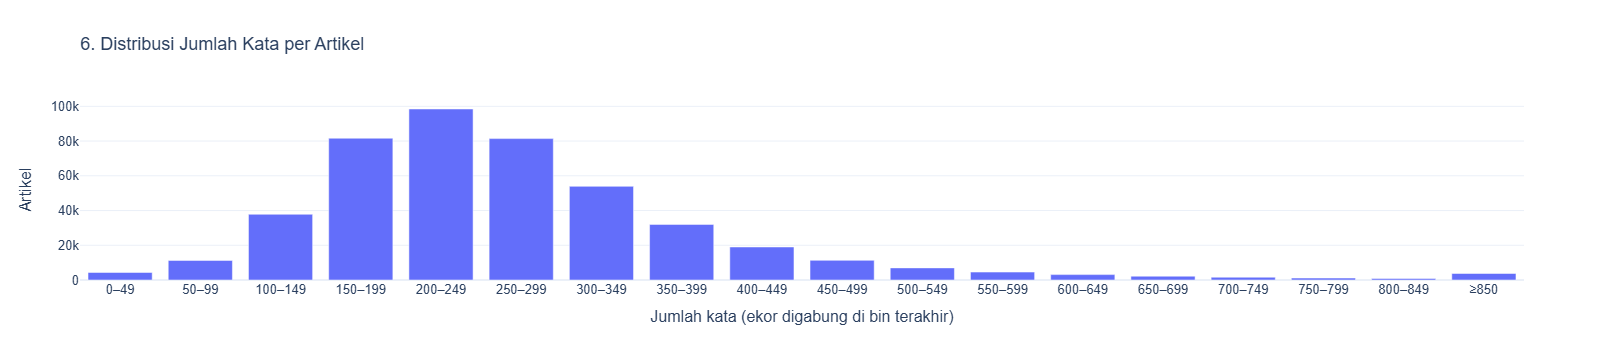

In [7]:
length = connection.execute("""
    SELECT AVG(word_count) AS mean_words, MEDIAN(word_count) AS median_words,
           QUANTILE_CONT(word_count, 0.99) AS p99,
           MIN(word_count) AS min_words, MAX(word_count) AS max_words,
           COUNT(*) FILTER (WHERE is_length_outlier) AS outliers
    FROM news
""").df().iloc[0]
tail_cutoff = max(100, int(math.ceil(float(length['p99']) / 50) * 50))
histogram = connection.execute("""
    SELECT LEAST(CAST(FLOOR(word_count / 50.0) * 50 AS INTEGER), ?) AS bin_start,
           COUNT(*) AS artikel
    FROM news GROUP BY bin_start ORDER BY bin_start
""", [tail_cutoff]).df()
histogram['rentang_kata'] = [
    f'{int(start)}–{int(start) + 49}' if start < tail_cutoff else f'≥{tail_cutoff}'
    for start in histogram['bin_start']
]
assert int(histogram['artikel'].sum()) == total
fig = px.bar(histogram, x='rentang_kata', y='artikel',
             labels={'rentang_kata': 'Jumlah kata (ekor digabung di bin terakhir)', 'artikel': 'Artikel'},
             title='6. Distribusi Jumlah Kata per Artikel')
show_and_save(fig, '06_article_length_distribution')


## 7. Perubahan Volume Lima Sumber Terbesar

Pemilihan lima sumber menggunakan jumlah artikel satu tahun penuh. Sumbu waktu
memuat semua bulan; grafik menunjukkan volume sumber terpilih, bukan seluruh media Indonesia.


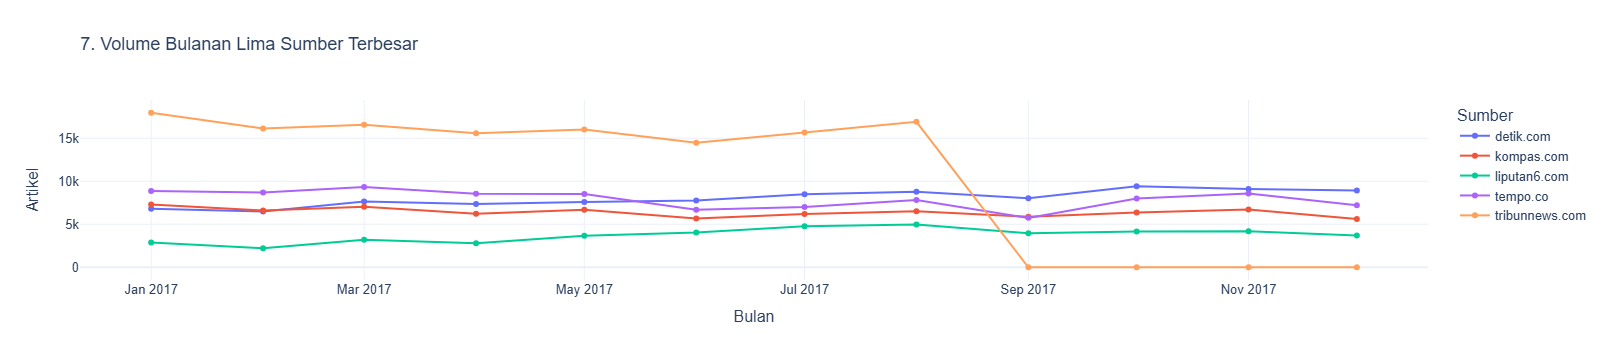

In [8]:
top_source_trend = connection.execute("""
    WITH top_sources AS (
        SELECT source FROM news GROUP BY source ORDER BY COUNT(*) DESC, source LIMIT 5
    ), months AS (SELECT DISTINCT bulan FROM calendar), counts AS (
        SELECT month AS bulan, source, COUNT(*) AS artikel
        FROM news WHERE source IN (SELECT source FROM top_sources) GROUP BY month, source
    )
    SELECT m.bulan, t.source AS sumber, COALESCE(c.artikel, 0) AS artikel
    FROM months m CROSS JOIN top_sources t
    LEFT JOIN counts c ON c.bulan = m.bulan AND c.source = t.source
    ORDER BY m.bulan, t.source
""").df()
top_source_trend['label_bulan'] = pd.to_datetime(top_source_trend['bulan']).dt.strftime('%Y-%m')
fig = px.line(top_source_trend, x='label_bulan', y='artikel', color='sumber', markers=True,
              labels={'label_bulan': 'Bulan', 'artikel': 'Artikel', 'sumber': 'Sumber'},
              title='7. Volume Bulanan Lima Sumber Terbesar')
show_and_save(fig, '07_source_monthly_trend')


## 8. Rata-rata dan Median Panjang Artikel per Bulan

Kedua statistik memakai jumlah kata asli. Hover juga mencantumkan proporsi flag outlier.


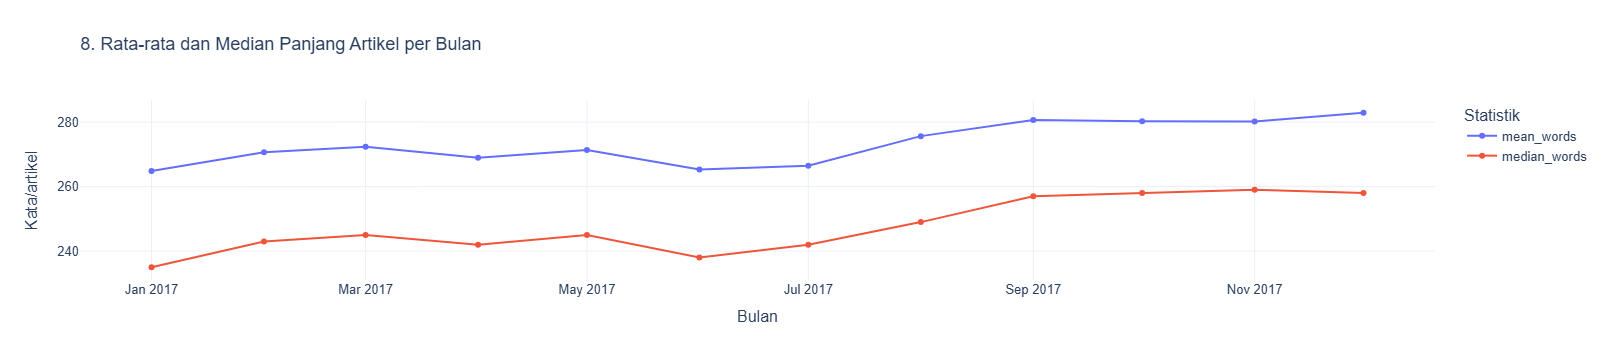

In [9]:
length_monthly = connection.execute("""
    SELECT month AS bulan, COUNT(*) AS artikel, AVG(word_count) AS mean_words,
           MEDIAN(word_count) AS median_words,
           100.0 * COUNT(*) FILTER (WHERE is_length_outlier) / COUNT(*) AS outlier_percent
    FROM news GROUP BY month ORDER BY month
""").df()
length_monthly['label_bulan'] = pd.to_datetime(length_monthly['bulan']).dt.strftime('%Y-%m')
length_long = length_monthly.melt(id_vars=['label_bulan', 'artikel', 'outlier_percent'],
                                 value_vars=['mean_words', 'median_words'],
                                 var_name='statistik', value_name='jumlah_kata')
fig = px.line(length_long, x='label_bulan', y='jumlah_kata', color='statistik', markers=True,
              hover_data=['artikel', 'outlier_percent'],
              labels={'label_bulan': 'Bulan', 'jumlah_kata': 'Kata/artikel', 'statistik': 'Statistik'},
              title='8. Rata-rata dan Median Panjang Artikel per Bulan')
show_and_save(fig, '08_monthly_article_length')


## Insight Analitik yang Didukung Data

Tujuh temuan berikut menggunakan tabel agregasi seluruh data dan hasil cleaning.
Temuan deskriptif tidak menyimpulkan penyebab perubahan atau mewakili seluruh berita Indonesia.


In [10]:
most_month = monthly.sort_values(['artikel', 'label_bulan'], ascending=[False, True]).iloc[0]
least_month = monthly.sort_values(['artikel', 'label_bulan']).iloc[0]
busiest_day = weekday.sort_values(['rata_per_hari', 'weekday'], ascending=[False, True]).iloc[0]
top5_share = float(sources.head(5)['persentase'].sum())
top_source = sources.iloc[0]
weekdays = weekday[weekday['weekday'] <= 5]
weekends = weekday[weekday['weekday'] >= 6]
weekday_rate = float(weekdays['artikel'].sum() / weekdays['hari_kalender'].sum())
weekend_rate = float(weekends['artikel'].sum() / weekends['hari_kalender'].sum())
coverage_days = int(daily['ada_artikel'].sum())
empty_days = len(daily) - coverage_days

if known_time_rows:
    by_hour = hourly.groupby('jam', as_index=False)['artikel'].sum()
    peak = by_hour.sort_values(['artikel', 'jam'], ascending=[False, True]).iloc[0]
    hour_insight = (
        f"Jam tercatat dengan artikel terbanyak adalah {int(peak['jam']):02d}.00 "
        f"({int(peak['artikel']):,} artikel; {100 * peak['artikel'] / known_time_rows:.2f}% "
        f"dari {known_time_rows:,} artikel dengan informasi jam). "
        f"Sebanyak {total - known_time_rows:,} artikel tanpa jam dikeluarkan dari heatmap."
    )
else:
    hour_insight = (
        f"Seluruh {total:,} artikel hanya memiliki tanggal atau tidak memiliki jam yang eksplisit. "
        "Puncak jam publikasi tidak dapat disimpulkan; heatmap diberi anotasi keterbatasan."
    )

insights = [
    f"Volume bulanan: {most_month['label_bulan']} tertinggi dengan {int(most_month['artikel']):,} "
    f"artikel ({most_month['persentase']:.2f}% korpus), sedangkan {least_month['label_bulan']} "
    f"terendah dengan {int(least_month['artikel']):,}. Rata-rata pada bulan tertinggi adalah "
    f"{most_month['rata_per_hari']:.2f} artikel/hari kalender (grafik 2).",
    f"Pola hari: {busiest_day['hari']} mempunyai rata-rata tertinggi "
    f"({busiest_day['rata_per_hari']:.2f} artikel/hari kalender). Rata-rata Senin–Jumat "
    f"{weekday_rate:.2f}, dibanding Sabtu–Minggu {weekend_rate:.2f}. "
    "Perhitungan memperhitungkan jumlah hari masing-masing (grafik 3).",
    f"Konsentrasi sumber: {len(sources):,} label sumber tercatat. "
    f"Lima label teratas menyumbang {top5_share:.2f}% artikel; sumber terbesar "
    f"{top_source['sumber']} menyumbang {top_source['persentase']:.2f}%. "
    "Komposisi ini membatasi generalisasi terhadap sumber lain (grafik 4 dan 7).",
    hour_insight + ' Lihat grafik 5.',
    f"Panjang teks: rata-rata {length['mean_words']:.2f} kata, median "
    f"{length['median_words']:.2f}, dan persentil 99 {length['p99']:.2f}. "
    f"Sebanyak {int(length['outliers']):,} artikel ({100 * length['outliers'] / total:.2f}%) "
    "ditandai outlier IQR dan tetap dianalisis menggunakan panjang asli (grafik 6 dan 8).",
    f"Kualitas data: {CLEANING['rows_raw']:,} artikel mentah menghasilkan {total:,} artikel bersih "
    f"({CLEANING['retained_percent']:.2f}% dipertahankan), setelah mengarantina "
    f"{CLEANING['rows_rejected']:,} artikel dan menghapus {CLEANING['duplicates_removed']:,} "
    "salinan duplikat. Jumlah baris telah direkonsiliasi dan seluruh validasi SQL lulus (notebook 02).",
    f"Cakupan waktu: arsip memiliki artikel pada {coverage_days} dari 365 hari "
    f"({100 * coverage_days / 365:.2f}%). Ada {empty_days} hari tanpa artikel dalam dataset. "
    "Hari kosong dapat mencerminkan keterbatasan pengumpulan; penyebabnya perlu sumber tambahan (grafik 1).",
]
report = '# Insight Analisis Berita Indonesia 2017\n\n'
report += f'Artikel bersih: {total:,}. Input SHA-256: `{CLEANING["clean_parquet_sha256"]}`.\n\n'
report += '\n\n'.join(f'{i}. {text}' for i, text in enumerate(insights, 1))
report += '\n\n## Visualisasi Interaktif\n\n'
report += '\n'.join(f'- [{title}](figures/{name}.html)' for name, title in figures.items())
report += (
    '\n\n## Batas Interpretasi\n\n'
    'Unit analisis adalah artikel, bukan peristiwa unik. Dataset merupakan arsip pengumpulan, '
    'bukan sensus seluruh publikasi Indonesia. Tidak ada inferensi kausal. '
    'Timestamp tanpa offset diasumsikan mengikuti jam WIB; jam yang tidak tersedia tidak diimputasi. '
    'Median dan persentil menghitung seluruh korpus, sementara IQR berasal dari artikel valid sebelum deduplikasi.\n'
)
(PROJECT_ROOT / 'output/insights.md').write_text(report, encoding='utf-8')
write_json(PROJECT_ROOT / 'output/eda_summary.json', {
    'rows_analysed': total, 'clean_parquet_sha256': CLEANING['clean_parquet_sha256'],
    'visualisations': [{'file': f'output/figures/{name}.html', 'title': title} for name, title in figures.items()],
    'insights': insights, 'calendar_days': 365, 'days_with_articles': coverage_days,
    'known_time_rows': known_time_rows,
})
assert len(figures) == 8 and len(insights) >= 5
display(Markdown(report))
connection.close()


# Insight Analisis Berita Indonesia 2017

Artikel bersih: 455,360. Input SHA-256: `ba3c4d94dc63a31d19d102127fbb993e80d097959600bb3cc2aca33a2f4fcea6`.

1. Volume bulanan: 2017-08 tertinggi dengan 46,745 artikel (10.27% korpus), sedangkan 2017-09 terendah dengan 25,177. Rata-rata pada bulan tertinggi adalah 1507.90 artikel/hari kalender (grafik 2).

2. Pola hari: Rabu mempunyai rata-rata tertinggi (1518.33 artikel/hari kalender). Rata-rata Senin–Jumat 1445.87, dibanding Sabtu–Minggu 756.51. Perhitungan memperhitungkan jumlah hari masing-masing (grafik 3).

3. Konsentrasi sumber: 6 label sumber tercatat. Lima label teratas menyumbang 97.03% artikel; sumber terbesar tribunnews.com menyumbang 28.40%. Komposisi ini membatasi generalisasi terhadap sumber lain (grafik 4 dan 7).

4. Jam tercatat dengan artikel terbanyak adalah 15.00 (33,759 artikel; 7.41% dari 455,360 artikel dengan informasi jam). Sebanyak 0 artikel tanpa jam dikeluarkan dari heatmap. Lihat grafik 5.

5. Panjang teks: rata-rata 272.35 kata, median 246.00, dan persentil 99 804.00. Sebanyak 20,799 artikel (4.57%) ditandai outlier IQR dan tetap dianalisis menggunakan panjang asli (grafik 6 dan 8).

6. Kualitas data: 455,678 artikel mentah menghasilkan 455,360 artikel bersih (99.93% dipertahankan), setelah mengarantina 52 artikel dan menghapus 266 salinan duplikat. Jumlah baris telah direkonsiliasi dan seluruh validasi SQL lulus (notebook 02).

7. Cakupan waktu: arsip memiliki artikel pada 365 dari 365 hari (100.00%). Ada 0 hari tanpa artikel dalam dataset. Hari kosong dapat mencerminkan keterbatasan pengumpulan; penyebabnya perlu sumber tambahan (grafik 1).

## Visualisasi Interaktif

- [1. Jumlah Artikel Harian dan Rata-rata 7 Hari](figures/01_daily_trend.html)
- [2. Jumlah Artikel per Bulan](figures/02_monthly_volume.html)
- [3. Intensitas Artikel Menurut Hari dalam Minggu](figures/03_weekday_pattern.html)
- [4. Sepuluh Sumber dengan Artikel Terbanyak](figures/04_source_composition.html)
- [5. Hari × Jam Publikasi (455,360 artikel dengan jam)](figures/05_weekday_hour_heatmap.html)
- [6. Distribusi Jumlah Kata per Artikel](figures/06_article_length_distribution.html)
- [7. Volume Bulanan Lima Sumber Terbesar](figures/07_source_monthly_trend.html)
- [8. Rata-rata dan Median Panjang Artikel per Bulan](figures/08_monthly_article_length.html)

## Batas Interpretasi

Unit analisis adalah artikel, bukan peristiwa unik. Dataset merupakan arsip pengumpulan, bukan sensus seluruh publikasi Indonesia. Tidak ada inferensi kausal. Timestamp tanpa offset diasumsikan mengikuti jam WIB; jam yang tidak tersedia tidak diimputasi. Median dan persentil menghitung seluruh korpus, sementara IQR berasal dari artikel valid sebelum deduplikasi.
